### What is the problem with SimpleRNN?
It's called the Vanishing Gradient Problem.

Let's understand it intuitively.

During training, a neural network learns by calculating errors and sending gradients backwards through the network. In RNNs, this process travels backwards through time. This is called Backpropagation Through Time (BPTT).

Suppose the sentence is:
"I thought this movie would be boring because the trailer was terrible, but surprisingly, it was absolutely fantastic!"

The model needs to understand the relationship between words that are far apart.

But as gradients travel backwards through many time steps, they can become extremely small.

This means:
- Earlier words may contribute very little to learning.
- The network struggles to learn long-term dependencies.
- Important information from earlier in the sequence can be lost.

#### LSTM stands for Long Short-Term Memory.

It was designed to help recurrent networks retain and control information over longer sequences.

It introduces:
- A Cell State (long-term memory pathway).
- A Hidden State (information passed to the next time step).
- Three gates to control information.
Think of LSTM as an improved memory system for RNNs.

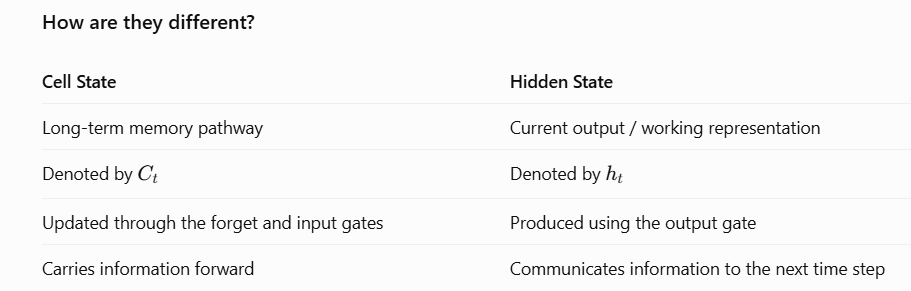

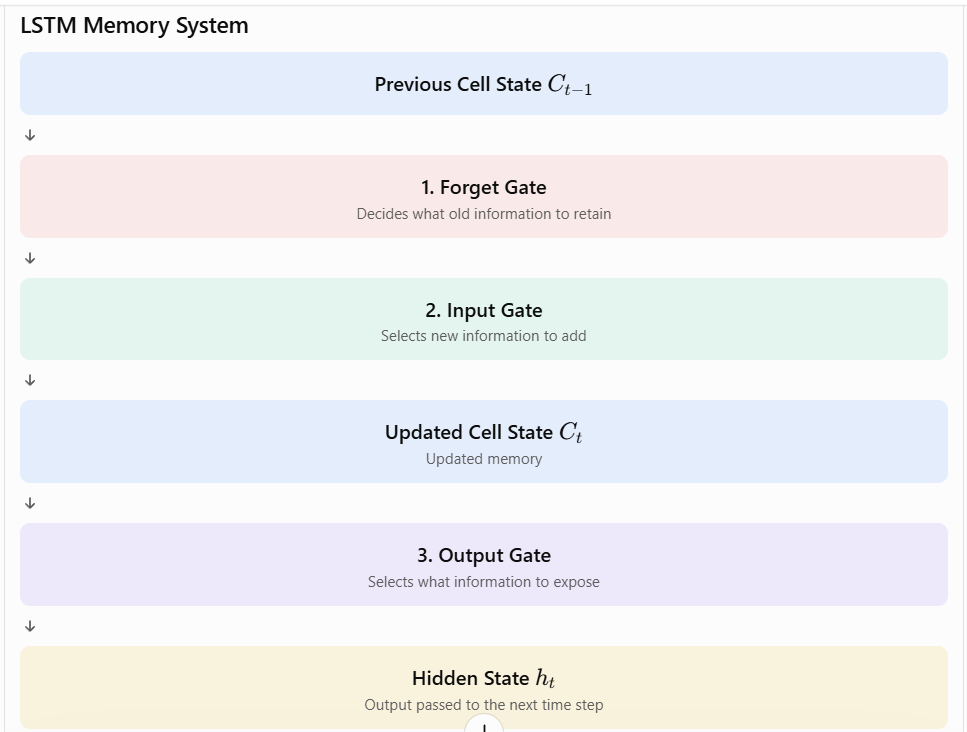

### GRU Introduction
GRU stands for Gated Recurrent Unit.

It is another type of recurrent neural network architecture, like LSTM.

GRU was introduced to provide a gated memory mechanism with a simpler architecture.

Remember LSTM has:
- Three gates.
- Cell State.
- Hidden State.
GRU simplifies this structure.

It uses two gates:
1. Update Gate
2. Reset Gate
And it does not maintain a separate cell state like LSTM. Its hidden state carries the memory.

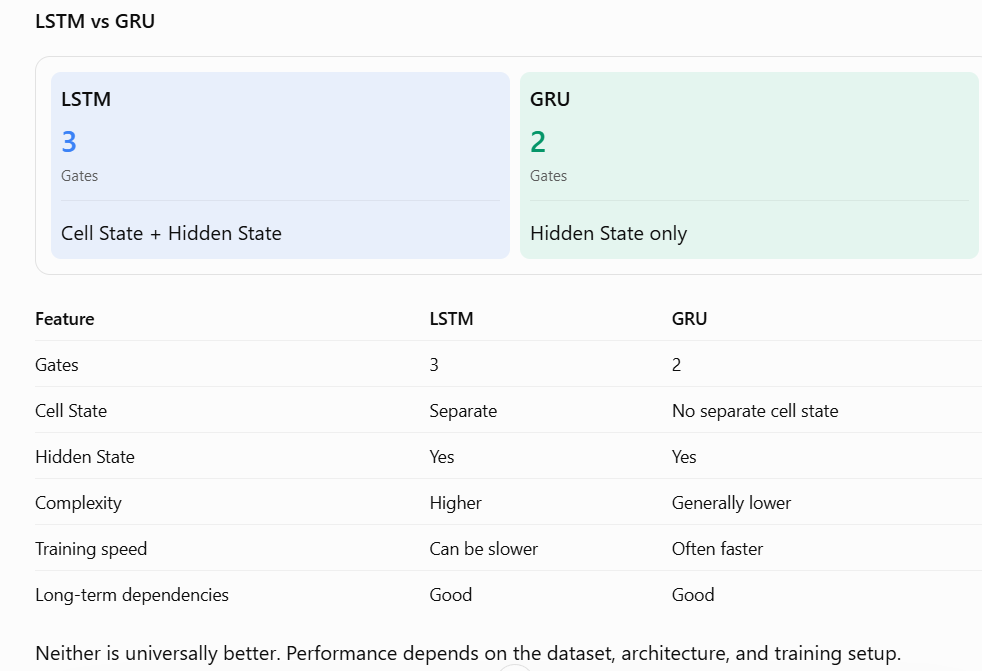

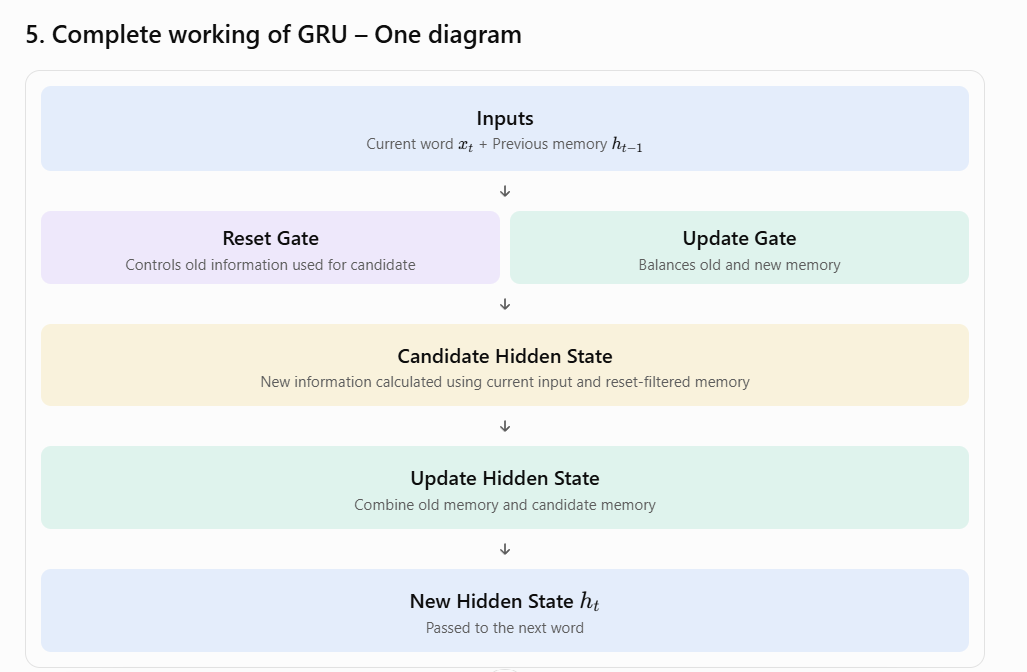

In [211]:
import pandas as pd

In [212]:
data=pd.read_json('News_Category_Dataset_v3.json', lines=True)

In [213]:
data.head()

,link,headline,category,short_description,authors,date
0,https://www.huffpost.com/entry/covid-boosters-...,Over 4 Million Americans Roll Up Sleeves For O...,U.S. NEWS,Health experts said it is too early to predict...,"Carla K. Johnson, AP",2022-09-23
1,https://www.huffpost.com/entry/american-airlin...,"American Airlines Flyer Charged, Banned For Li...",U.S. NEWS,He was subdued by passengers and crew when he ...,Mary Papenfuss,2022-09-23
2,https://www.huffpost.com/entry/funniest-tweets...,23 Of The Funniest Tweets About Cats And Dogs ...,COMEDY,"""Until you have a dog you don't understand wha...",Elyse Wanshel,2022-09-23
3,https://www.huffpost.com/entry/funniest-parent...,The Funniest Tweets From Parents This Week (Se...,PARENTING,"""Accidentally put grown-up toothpaste on my to...",Caroline Bologna,2022-09-23
4,https://www.huffpost.com/entry/amy-cooper-lose...,Woman Who Called Cops On Black Bird-Watcher Lo...,U.S. NEWS,Amy Cooper accused investment firm Franklin Te...,Nina Golgowski,2022-09-22


In [214]:
data.columns

Index(['link', 'headline', 'category', 'short_description', 'authors', 'date'], dtype='str')

In [215]:
data=data['short_description'].head(200)

In [216]:
data.head()

0    Health experts said it is too early to predict...
1    He was subdued by passengers and crew when he ...
2    "Until you have a dog you don't understand wha...
3    "Accidentally put grown-up toothpaste on my to...
4    Amy Cooper accused investment firm Franklin Te...
Name: short_description, dtype: str

In [217]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, GRU

In [218]:
tokenizer=Tokenizer( oov_token="<OOV>")

In [219]:
tokenizer.fit_on_texts(data)

In [220]:
tokenizer.word_index

{'<OOV>': 1,
 'the': 2,
 'a': 3,
 'to': 4,
 'of': 5,
 'in': 6,
 'and': 7,
 'for': 8,
 'on': 9,
 'was': 10,
 'is': 11,
 'that': 12,
 'as': 13,
 'with': 14,
 'has': 15,
 'at': 16,
 'said': 17,
 'his': 18,
 'her': 19,
 'after': 20,
 'who': 21,
 '—': 22,
 'he': 23,
 'an': 24,
 'from': 25,
 'u': 26,
 'it': 27,
 'will': 28,
 'are': 29,
 'up': 30,
 'new': 31,
 's': 32,
 'be': 33,
 'one': 34,
 'out': 35,
 'about': 36,
 'have': 37,
 'this': 38,
 'year': 39,
 'over': 40,
 'president': 41,
 '”': 42,
 'but': 43,
 'former': 44,
 'by': 45,
 'more': 46,
 'first': 47,
 'when': 48,
 'storm': 49,
 'police': 50,
 'been': 51,
 'not': 52,
 'two': 53,
 'people': 54,
 'house': 55,
 'against': 56,
 'day': 57,
 'biden': 58,
 'or': 59,
 'you': 60,
 'could': 61,
 'she': 62,
 'water': 63,
 'sunday': 64,
 'into': 65,
 'their': 66,
 'there': 67,
 'told': 68,
 'they': 69,
 'made': 70,
 'reported': 71,
 'say': 72,
 'its': 73,
 'world': 74,
 'nearly': 75,
 'series': 76,
 'were': 77,
 'man': 78,
 'public': 79,
 'media'

In [221]:
len(tokenizer.word_index)

1911

In [222]:
data=tokenizer.texts_to_sequences(data)

In [223]:
data

[[149,
  515,
  17,
  27,
  11,
  516,
  83,
  4,
  517,
  150,
  518,
  258,
  259,
  30,
  14,
  2,
  519,
  84,
  520,
  5,
  2,
  31,
  521,
  2,
  26,
  32,
  260,
  8,
  2,
  522],
 [23,
  10,
  523,
  45,
  524,
  7,
  525,
  48,
  23,
  261,
  4,
  2,
  151,
  5,
  2,
  526,
  20,
  2,
  527,
  262,
  4,
  2,
  26,
  32,
  528,
  111,
  6,
  263,
  264],
 [112, 60, 37, 3, 529, 60, 152, 530, 153, 61, 33, 531],
 [532,
  533,
  534,
  30,
  535,
  9,
  154,
  536,
  537,
  7,
  23,
  538,
  155,
  113,
  10,
  539,
  18,
  265,
  14,
  3,
  266,
  540,
  541,
  6,
  542,
  543],
 [544,
  545,
  156,
  546,
  267,
  547,
  548,
  5,
  549,
  550,
  19,
  7,
  551,
  19,
  3,
  552,
  20,
  268,
  5,
  2,
  553,
  554,
  555,
  85,
  556],
 [2,
  557,
  39,
  114,
  157,
  10,
  558,
  269,
  16,
  2,
  559,
  266,
  270,
  9,
  560,
  62,
  10,
  271,
  561,
  86,
  20,
  19,
  158,
  71,
  19,
  562,
  159,
  17],
 [272,
  12,
  563,
  60,
  24,
  564,
  8,
  31,
  565,
  566,
  5

In [224]:
input_sequences=[]
for seq in data:
    if len(seq)<2:
        continue
    for i in range(1,len(seq)):
        ngram=seq[:i+1]
        input_sequences.append(ngram)

In [225]:
input_sequences

[[149, 515],
 [149, 515, 17],
 [149, 515, 17, 27],
 [149, 515, 17, 27, 11],
 [149, 515, 17, 27, 11, 516],
 [149, 515, 17, 27, 11, 516, 83],
 [149, 515, 17, 27, 11, 516, 83, 4],
 [149, 515, 17, 27, 11, 516, 83, 4, 517],
 [149, 515, 17, 27, 11, 516, 83, 4, 517, 150],
 [149, 515, 17, 27, 11, 516, 83, 4, 517, 150, 518],
 [149, 515, 17, 27, 11, 516, 83, 4, 517, 150, 518, 258],
 [149, 515, 17, 27, 11, 516, 83, 4, 517, 150, 518, 258, 259],
 [149, 515, 17, 27, 11, 516, 83, 4, 517, 150, 518, 258, 259, 30],
 [149, 515, 17, 27, 11, 516, 83, 4, 517, 150, 518, 258, 259, 30, 14],
 [149, 515, 17, 27, 11, 516, 83, 4, 517, 150, 518, 258, 259, 30, 14, 2],
 [149, 515, 17, 27, 11, 516, 83, 4, 517, 150, 518, 258, 259, 30, 14, 2, 519],
 [149,
  515,
  17,
  27,
  11,
  516,
  83,
  4,
  517,
  150,
  518,
  258,
  259,
  30,
  14,
  2,
  519,
  84],
 [149,
  515,
  17,
  27,
  11,
  516,
  83,
  4,
  517,
  150,
  518,
  258,
  259,
  30,
  14,
  2,
  519,
  84,
  520],
 [149,
  515,
  17,
  27,
  11,
  516

In [226]:
max_len=max([len(x) for x in input_sequences])

In [227]:
max_len

44

In [228]:
input_sequences=pad_sequences(input_sequences, maxlen=max_len, padding='pre')

In [229]:
input_sequences

array([[  0,   0,   0, ...,   0, 149, 515],
       [  0,   0,   0, ..., 149, 515,  17],
       [  0,   0,   0, ..., 515,  17,  27],
       ...,
       [  0,   0,   0, ..., 185,   5,   2],
       [  0,   0,   0, ...,   5,   2,  80],
       [  0,   0,   0, ...,   2,  80, 507]], shape=(4075, 44), dtype=int32)

In [230]:
X=input_sequences[:,:-1]
Y=input_sequences[:,-1]

In [231]:
Y[0]

np.int32(515)

In [232]:
Y=np.array(Y)

In [233]:
X[0]

array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0, 149], dtype=int32)

In [234]:

from sklearn.model_selection import train_test_split

In [235]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [236]:
vocab_size = max(tokenizer.word_index.values()) + 1

model = Sequential()

model.add(Embedding(vocab_size, 128, input_length=max_len-1, mask_zero=True))
model.add(LSTM(256))
model.add(Dense(vocab_size, activation='softmax'))

model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.build(input_shape=(None, max_len-1))
model.summary()

c:\Users\SHASHANK\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_7 (Embedding)         │ (None, 43, 128)        │       244,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 256)            │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1912)           │       491,384 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,130,360 (4.31 MB)

 Trainable params: 1,130,360 (4.31 MB)

 Non-trainable params: 0 (0.00 B)

In [237]:
model.fit(X_train, Y_train, epochs=10, validation_data=(X_test, Y_test))

Epoch 1/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 16s 117ms/step - accuracy: 0.0488 - loss: 7.2483 - val_accuracy: 0.0626 - val_loss: 7.1730
Epoch 2/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 12s 120ms/step - accuracy: 0.0531 - loss: 6.7060 - val_accuracy: 0.0601 - val_loss: 7.3184
Epoch 3/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 12s 116ms/step - accuracy: 0.0534 - loss: 6.4860 - val_accuracy: 0.0613 - val_loss: 7.4170
Epoch 4/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - accuracy: 0.0549 - loss: 6.2827 - val_accuracy: 0.0601 - val_loss: 7.5438
Epoch 5/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 11s 106ms/step - accuracy: 0.0571 - loss: 6.0581 - val_accuracy: 0.0736 - val_loss: 7.7604
Epoch 6/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 10s 100ms/step - accuracy: 0.0699 - loss: 5.7756 - val_accuracy: 0.0724 - val_loss: 8.0006
Epoch 7/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 11s 103ms/step - accuracy: 0.0776 - loss: 5.4605 - val_accuracy: 0.0687 - val_loss: 8.2689
Epoch 8/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 11s 106ms/step - accuracy: 0.0902 - loss: 5

In [238]:
model.save('text_generation_model.h5')

In [239]:
import pickle

with open('tokenizer.pickle', 'wb') as file:
    pickle.dump(tokenizer, file, protocol=pickle.HIGHEST_PROTOCOL)